# Import 

In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.utils import to_categorical
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import keras 
import tensorflow

from keras.utils import set_random_seed
import random

import gradio as gr
from PIL import Image 

seed = 9999
random.seed(seed) #python
np.random.seed(seed) #np
set_random_seed(seed) #keras

C:\Users\almut\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Reading 

In [2]:
train_df=keras.utils.image_dataset_from_directory(
    'train',
    image_size=(48, 48),
    seed=9999,
    color_mode="rgb"
)

test_df=keras.utils.image_dataset_from_directory(
    'test',
    image_size=(48, 48),
    seed=9999,
    shuffle=False,
    color_mode="rgb"
)


Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.


# Split

In [3]:
#train
X, y= zip(*train_df.as_numpy_iterator()) #zip seprates img from label
#convert batches in one array
X = np.concatenate(X)
y = np.concatenate(y)

#test
X_test, y_test = zip(*test_df.as_numpy_iterator())
X_test = np.concatenate(X_test)
y_test = np.concatenate(y_test)

In [4]:
X.shape 

(28709, 48, 48, 3)

In [5]:
y.shape #label only

(28709,)

In [6]:
X_test.shape

(7178, 48, 48, 3)

In [7]:
y_test.shape

(7178,)

# Normalize 

In [8]:
X= X /255.0 #num between 0-1 for img

In [9]:
X_test= X_test/255.0

# Inspect Data

In [10]:
train_df.class_names

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

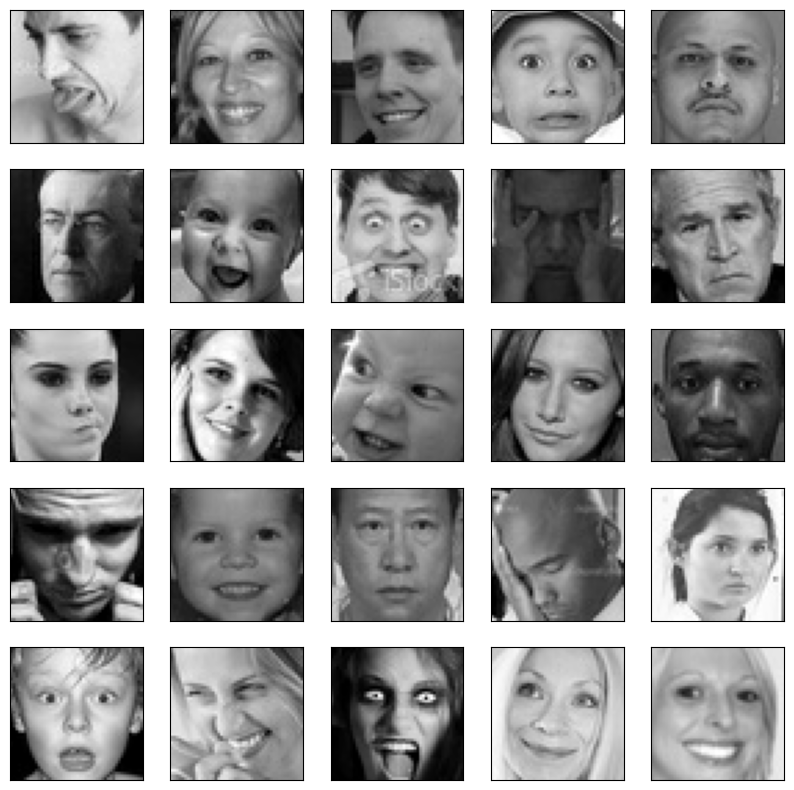

In [11]:
class_names = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

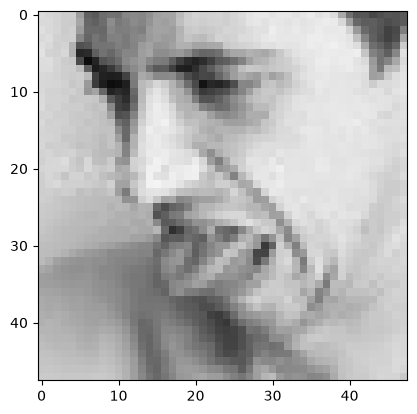

In [12]:
plt.imshow(X[0])
plt.show()

# Baseline Model 

In [13]:
# Import
from keras.layers import Dense, Activation , Flatten
from keras.models import Sequential
from keras.losses import CategoricalCrossentropy

#Step2
model = Sequential([Flatten(input_shape=( 48, 48, 3)),
    Dense (100,activation='relu'),
    Dense(73, activation='relu'),
                     
    Dense(7,activation='softmax') ]) #7 clases

# STep3: Compile
model.compile(loss='sparse_categorical_crossentropy',metrics=['acc'] ) 


#STep4: Fitting
model.fit(X,y, validation_split=0.2, epochs=1, shuffle=False)


model.summary()

C:\Users\almut\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.2505 - loss: 1.9041 - val_acc: 0.2344 - val_loss: 1.7956


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 6912)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 100)                 │         691,300 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 73)                  │           7,373 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 7)                   │             518 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,398,384 (5.33 MB)

 Trainable params: 699,191 (2.67 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 699,193 (2.67 MB)

In [14]:
model.weights

[<Variable path=sequential/dense/kernel, shape=(6912, 100), dtype=float32, value=[[-2.7369183e-02 -2.7506009e-02  2.8393085e-03 ... -1.8878905e-02
   -1.4229212e-05 -3.0459264e-02]
  [ 1.1233350e-02  2.1254983e-02 -2.5652925e-02 ...  1.1331760e-02
    6.7527234e-03  2.1706978e-02]
  [-2.1673236e-02 -5.3353012e-03  3.6369660e-04 ...  2.2082709e-02
    5.3887754e-03  1.5230254e-02]
  ...
  [-2.4518102e-02  2.4327071e-02 -1.4513719e-03 ...  1.6838871e-02
   -2.2445120e-02 -2.7087463e-02]
  [-2.1104869e-02  1.9429663e-02  2.1045026e-04 ... -2.7138414e-02
   -1.5439349e-04  1.5633800e-03]
  [-2.2472840e-02  1.9932972e-02 -5.1353155e-03 ...  6.7815930e-03
   -1.8920111e-02  2.1603530e-02]]>,
 <Variable path=sequential/dense/bias, shape=(100,), dtype=float32, value=[-3.1580243e-03 -3.0804761e-03 -3.1556566e-03 -3.1614134e-03
  -3.1619761e-03 -2.3516852e-03 -3.6918707e-03 -2.8891675e-04
  -5.4721930e-03  7.2943963e-02 -3.1538778e-03 -3.1459951e-03
  -2.2017458e-03  4.4044510e-02 -1.5751399e-03

# New Model

In [15]:
#the data is not balanced 
import pandas as pd
pd.Series(y).value_counts()

3    7215
4    4965
5    4830
2    4097
0    3995
6    3171
1     436
Name: count, dtype: int64

In [25]:
#weight
from sklearn.utils import compute_class_weight 

c_weights = compute_class_weight(class_weight="balanced", 
                                  classes=np.unique(y), 
                                  y=y)
class_weight_dict = dict(zip(np.unique(y), c_weights))

In [34]:
#callback
from keras.callbacks import EarlyStopping, ModelCheckpoint
early_stopping_callback =  EarlyStopping(monitor='val_accuracy',patience=5, mode='max') #wait 3 epocs if val acc didnt import =stop

In [39]:
# Import
from keras.layers import Dense, Activation , Flatten, Dropout
from keras.models import Sequential
from keras.losses import CategoricalCrossentropy

#Step2
model = Sequential([
    Input(shape=(48, 48, 3)),
    Flatten(),
    Dense (256,activation='relu'),
    Dense (128,activation='relu'),
    Dense(64, activation='relu'),
#op
                     
    Dense(7,activation='softmax') ]) #7 clases

# STep3: Compile
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',metrics=['accuracy'] ) 


#STep4: Fitting
history = model.fit(X,y, validation_split=0.2, epochs=20,batch_size=32, shuffle=True, class_weight=class_weight_dict) 


model.summary()

Epoch 1/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.1736 - loss: 1.9612 - val_accuracy: 0.2887 - val_loss: 1.8430
Epoch 2/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.2225 - loss: 1.8944 - val_accuracy: 0.3025 - val_loss: 1.8373
Epoch 3/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.2444 - loss: 1.8674 - val_accuracy: 0.1942 - val_loss: 1.9157
Epoch 4/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.2481 - loss: 1.8477 - val_accuracy: 0.1688 - val_loss: 1.9579
Epoch 5/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.2512 - loss: 1.8291 - val_accuracy: 0.2273 - val_loss: 1.8639
Epoch 6/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.2589 - loss: 1.8159 - val_accuracy: 0.2590 - val_loss: 1.8104
Epoch 7/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.2690 - loss: 1.7995 - val_accuracy: 0.2874 - val_loss: 1.7785
Epoch 8/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.2749 - loss: 1.7900 - val

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_6 (Flatten)                  │ (None, 6912)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 256)                 │       1,769,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 7)                   │             455 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,434,007 (20.73 MB)

 Trainable params: 1,811,335 (6.91 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,622,672 (13.82 MB)

In [40]:
hist_df= pd.DataFrame(history.history) 

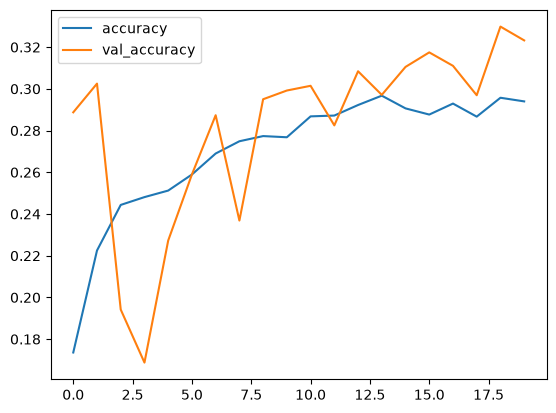

In [42]:
hist_df[['accuracy','val_accuracy']].plot();

In [41]:
pd.Series(np.argmax(model.predict(X), axis=1)).value_counts() #predictions

898/898 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step


3    8316
4    7689
6    3986
5    3698
1    3322
2    1528
0     170
Name: count, dtype: int64

In [43]:
y_pred = model.predict(X_test)
y_pred=np.argmax(y_pred,axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


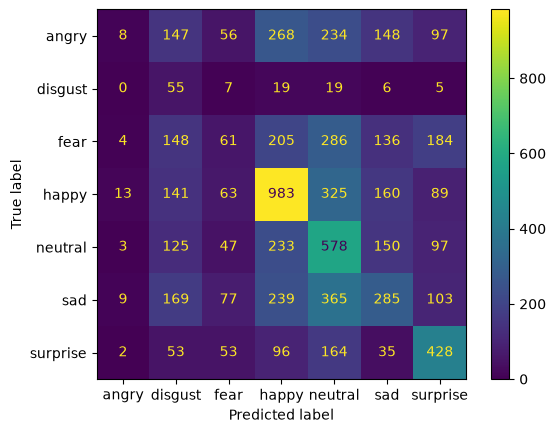

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=test_df.class_names
)

plt.show()

In [45]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.21      0.01      0.02       958
           1       0.07      0.50      0.12       111
           2       0.17      0.06      0.09      1024
           3       0.48      0.55      0.52      1774
           4       0.29      0.47      0.36      1233
           5       0.31      0.23      0.26      1247
           6       0.43      0.52      0.47       831

    accuracy                           0.33      7178
   macro avg       0.28      0.33      0.26      7178
weighted avg       0.32      0.33      0.31      7178



# Deploy

In [53]:
#! pip install gradio

   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
    --------------------------------------- 0.5/31.4 MB 2.4 MB/s eta 0:00:13
   - -------------------------------------- 1.0/31.4 MB 2.5 MB/s eta 0:00:13
   -- ------------------------------------- 1.8/31.4 MB 2.7 MB/s eta 0:00:11
   --- ------------------------------------ 2.6/31.4 MB 3.1 MB/s eta 0:00:10
   --- ------------------------------------ 2.9/31.4 MB 3.1 MB/s eta 0:00:10
   ---- ----------------------------------- 3.7/31.4 MB 2.8 MB/s eta 0:00:10
   ----- ---------------------------------- 3.9/31.4 MB 2.7 MB/s eta 0:00:11
   ------ --------------------------------- 5.0/31.4 MB 2.9 MB/s eta 0:00:09
   ------- -------------------------------- 6.0/31.4 MB 3.2 MB/s eta 0:00:08
   --------- ------------------------------ 7.1/31.4 MB 3.3 MB/s eta 0:00:08
   ---------- ----------------------------- 7.9/31.4 MB 3.3 MB/s eta 0:00:08
   ----------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [68]:
class_names = [ '😠 Angry','🤢 Disgust','😨 Fear', '😊 Happy', '😐 Neutral',  '😢 Sad', '😲 Surprise']

#prediction function 
def predict_emo(img):
    img = Image.fromarray(img).convert("RGB").resize((48,48)) 
    img = np.array(img)/ 255.0 
    img = np.expand_dims(img,axis=0)
    pred= model.predict(img, verbose=0)[0]
    return dict(zip(class_names,pred.tolist()))

#app interface
app = gr.Interface(
    fn=predict_emo,
    inputs=gr.Image(sources=["upload", "webcam"], type="numpy"),
    outputs=gr.Label(num_top_classes=7),
    title="Emotion Recognition Predection☺️",
    description="Please upload or take an image via web cam!"
)

app.launch(inline=True)


* Running on local URL:  http://127.0.0.1:7868
* To create a public link, set `share=True` in `launch()`.


Traceback (most recent call last):
  File "C:\Users\almut\AppData\Local\Programs\Python\Python312\Lib\site-packages\gradio\queueing.py", line 848, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\almut\AppData\Local\Programs\Python\Python312\Lib\site-packages\gradio\route_utils.py", line 417, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\almut\AppData\Local\Programs\Python\Python312\Lib\site-packages\gradio\blocks.py", line 2698, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\almut\AppData\Local\Programs\Python\Python312\Lib\site-packages\gradio\blocks.py", line 1963, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\almut\AppData\Local\P